# WorldTides

https://www.worldtides.info

In [1]:
from urllib.parse import urlencode
from urllib.request import urlopen
import json
import pandas as pd
import datetime

#https://www.worldtides.info/settings
import os 
api_key = os.environ.get("WORLD_TIDES_API_KEY", "YOUR_API_KEY_HERE")
print(f"Using API Key: {api_key}")

Using API Key: 26facd06-7daf-44b7-a006-2e5fce119fb0


In [2]:


class WorldTides:
    def __init__(self, key, lat, lon):
        self.key = key
        self.lat = lat
        self.lon = lon
        self.base = "https://www.worldtides.info/api/v3"

    def get_extremes(self, date: datetime.date, duration: datetime.timedelta):
        return self._request("extremes", date, duration).get("extremes", [])

    def get_heights(self, date: datetime.date, duration: datetime.timedelta):
        return self._request("heights", date, duration).get("heights", [])

    def get_datums(self, date: datetime.date, duration: datetime.timedelta):
        return self._request("datums", date, duration).get("datums", [])
    
    def _request(self, flag, date: datetime.date, duration: datetime.timedelta):
        query = urlencode({
            "date": f"{date.year:04d}-{date.month:02d}-{date.day:02d}",
            "days": duration.days,
            "lat": self.lat,
            "lon": self.lon,
            "key": self.key,
        })
        query_url = f"{self.base}?{flag}&{query}"
        print(query_url)
        with urlopen(query_url, timeout=10) as response:
            data = json.loads(response.read().decode("utf-8"))
        if data.get("status", 200) != 200:
            raise RuntimeError(data.get("error", "WorldTides error"))
        return data


In [3]:
lat, lon =  38.7965, -9.0885

today = datetime.date.today()
duration = datetime.timedelta(days=3)
start_date = today - duration
print(f"Getting tide data from {start_date} to {today}")

tides = WorldTides(api_key, lat, lon)
extremes = tides.get_extremes(start_date, duration)
heights = tides.get_heights(start_date, duration)
datums = tides.get_datums(start_date, duration)


Getting tide data from 2026-11-17 to 2026-11-20
https://www.worldtides.info/api/v3?extremes&date=2026-11-17&days=3&lat=38.7965&lon=-9.0885&key=26facd06-7daf-44b7-a006-2e5fce119fb0
https://www.worldtides.info/api/v3?heights&date=2026-11-17&days=3&lat=38.7965&lon=-9.0885&key=26facd06-7daf-44b7-a006-2e5fce119fb0
https://www.worldtides.info/api/v3?datums&date=2026-11-17&days=3&lat=38.7965&lon=-9.0885&key=26facd06-7daf-44b7-a006-2e5fce119fb0


In [4]:
heights[:3]

[{'dt': 1794873600, 'date': '2026-11-17T00:00+0000', 'height': -0.407},
 {'dt': 1794875400, 'date': '2026-11-17T00:30+0000', 'height': -0.493},
 {'dt': 1794877200, 'date': '2026-11-17T01:00+0000', 'height': -0.544}]

In [5]:
ssh = pd.DataFrame(heights)
ssh["date"] = pd.to_datetime(ssh["date"])
ssh = ssh.set_index("date")
ssh.head()


,dt,height
date,,
2026-11-17 00:00:00+00:00,1794873600,-0.407
2026-11-17 00:30:00+00:00,1794875400,-0.493
2026-11-17 01:00:00+00:00,1794877200,-0.544
2026-11-17 01:30:00+00:00,1794879000,-0.560
2026-11-17 02:00:00+00:00,1794880800,-0.541


Text(0.5, 1.0, 'Tide Heights at -9.0885, 38.7965')

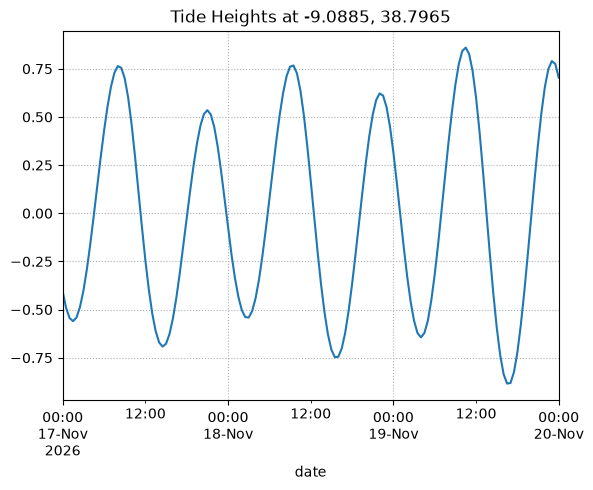

In [6]:
ax = ssh["height"].plot()
ax.grid(ls=":")
ax.set_title(f"Tide Heights at {lon:.4f}, {lat:.4f}")

In [7]:
fileout = f'tide_worldtides_{lat}_{lon}_{start_date}_{today}.csv'
print(f"Saving to {fileout}")
ssh.to_csv(fileout)

Saving to tide_worldtides_38.7965_-9.0885_2026-11-17_2026-11-20.csv
